<a href="https://colab.research.google.com/github/MariaVrett/Model-Evaluation/blob/main/Model_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Libraries

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math
import seaborn as sns
import scipy.stats as st
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

# Load Dataset and Info about the Dataset

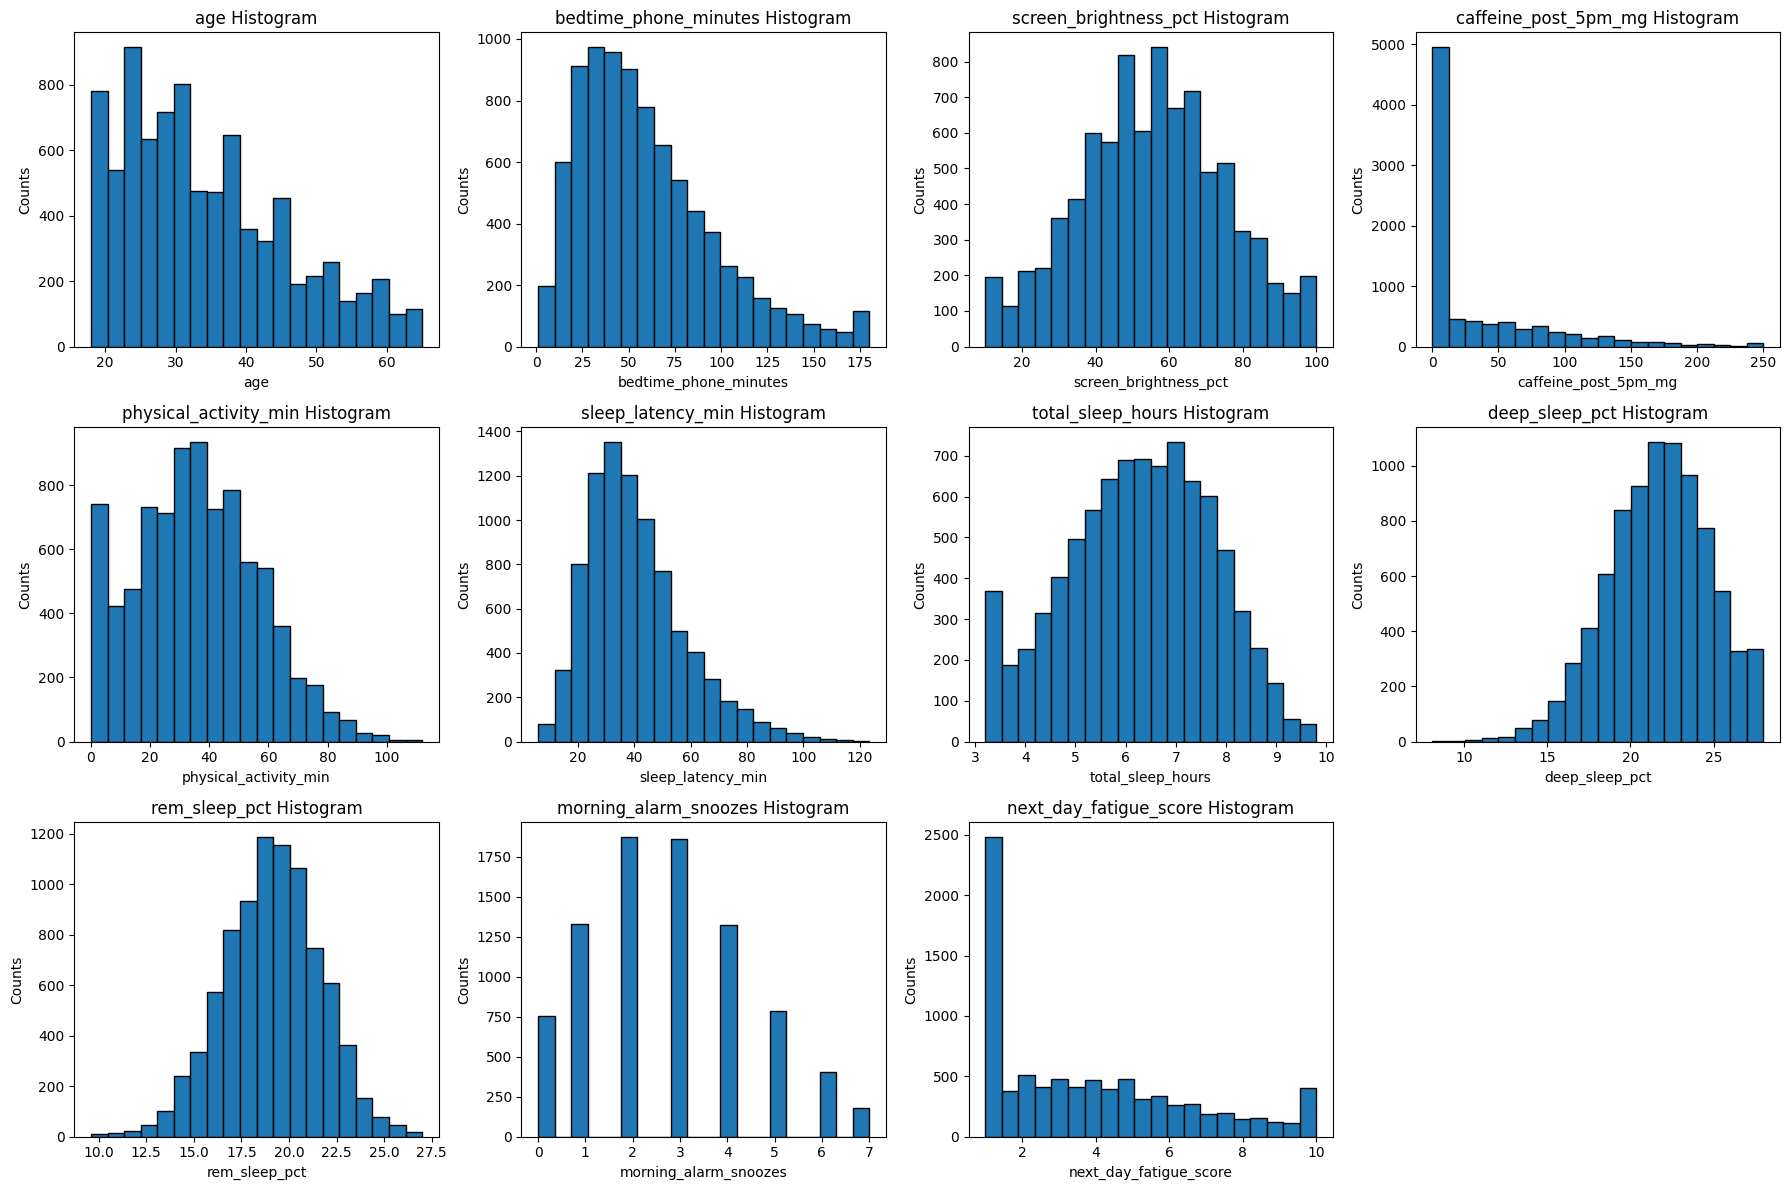

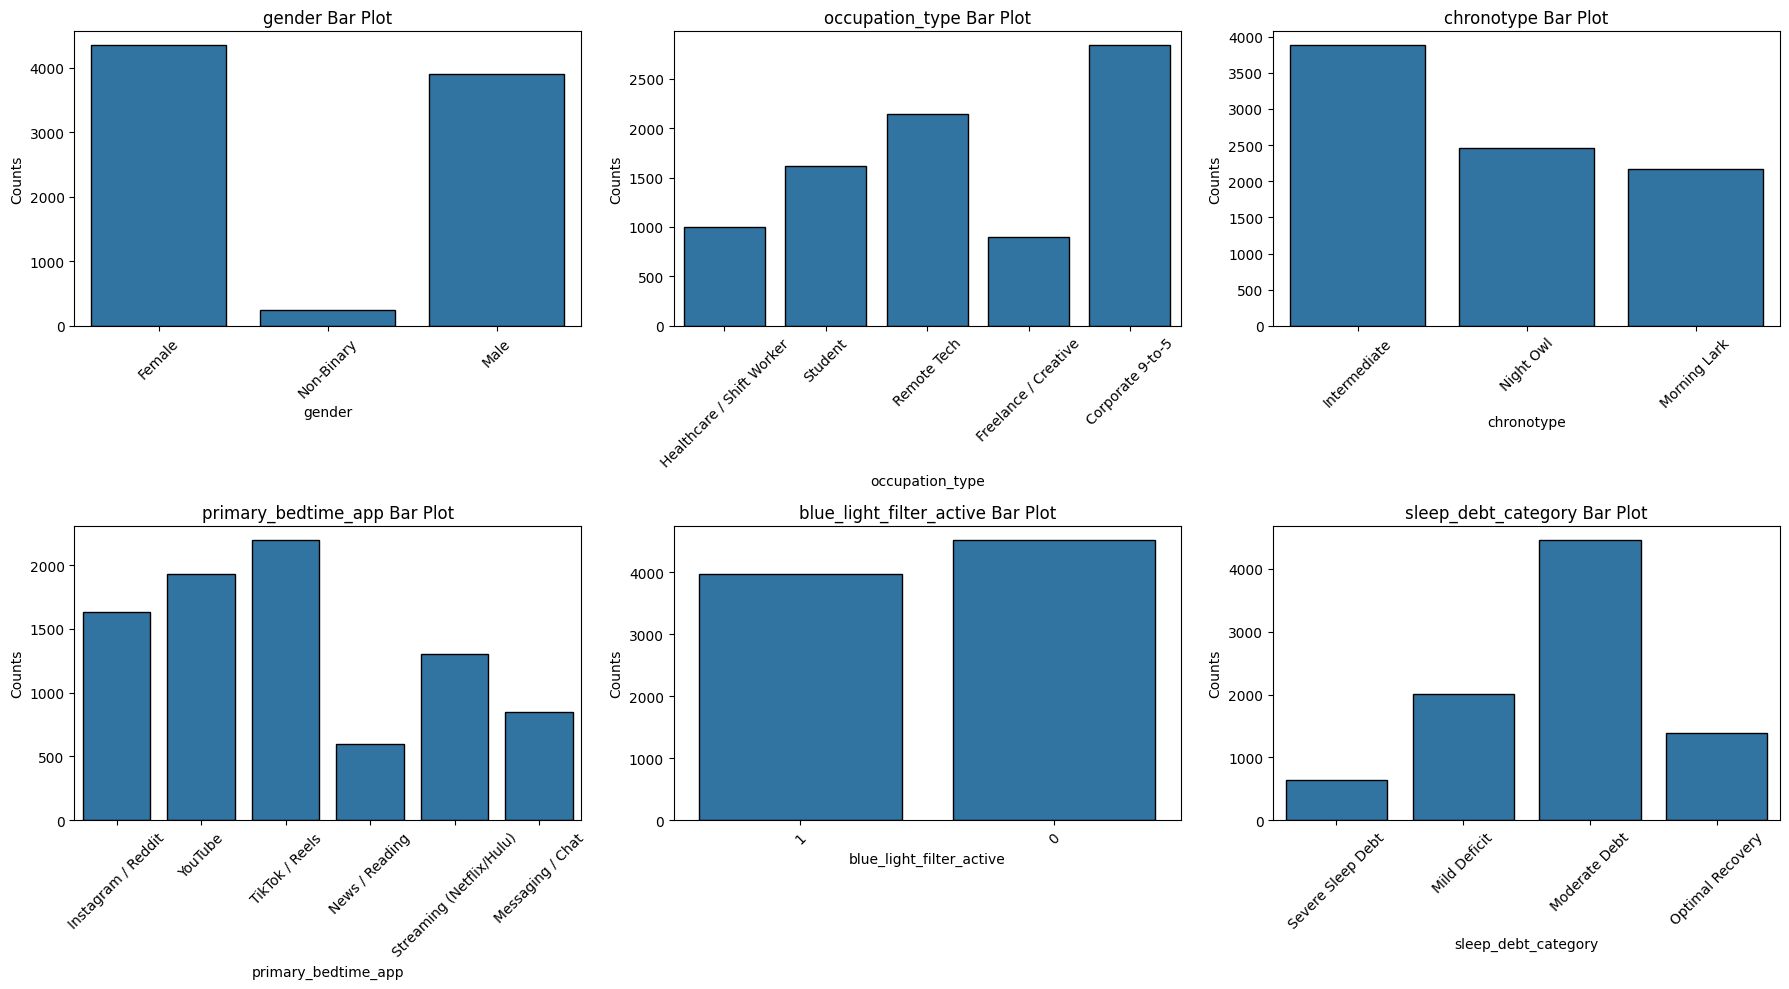

Class Distribution Percentages for 'sleep_debt_category':
sleep_debt_category
Moderate Debt        52.494118
Mild Deficit         23.576471
Optimal Recovery     16.317647
Severe Sleep Debt     7.611765
Name: proportion, dtype: float64


In [51]:
df = pd.read_csv('sleep.csv')

df['blue_light_filter_active'] = df['blue_light_filter_active'].astype(str)

if 'user_id' in df.columns:
    df = df.drop(columns=['user_id'])

#Histograms for Numerical Variables
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns
n_features = len(numeric_features)
cols = 4
rows = math.ceil(n_features / cols)
fig, axes = plt.subplots(rows, cols, figsize=(18, rows * 4))
axes = axes.flatten()
for i, feature in enumerate(numeric_features):
    df[feature].hist(bins=20, edgecolor='black', ax=axes[i])
    axes[i].set_title(f'{feature} Histogram')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Counts')
    axes[i].grid(False)
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


# Bar Plots for Categorical Variables
cat_features = df.select_dtypes(include=['object', 'category', 'bool']).columns
n_cat = len(cat_features)
cols_cat = 3
rows_cat = math.ceil(n_cat / cols_cat)
fig_cat, axes_cat = plt.subplots(rows_cat, cols_cat, figsize=(18, rows_cat * 5))
axes_cat = axes_cat.flatten()
for i, feature in enumerate(cat_features):
    sns.countplot(data=df, x=feature, ax=axes_cat[i], edgecolor='black')
    axes_cat[i].set_title(f'{feature} Bar Plot')
    axes_cat[i].set_xlabel(feature)
    axes_cat[i].set_ylabel('Counts')
    axes_cat[i].tick_params(axis='x', rotation=45)
for j in range(i + 1, len(axes_cat)):
    axes_cat[j].axis('off')

plt.tight_layout()
plt.show()

# Check for Class Imbalance in the Target Variable
print("Class Distribution Percentages for 'sleep_debt_category':")
print(df['sleep_debt_category'].value_counts(normalize=True) * 100)

It is an imbalanced class problem. The dataset suffers from significant class imbalance because the majority class 'Moderate Debt' accounts for 52.5% of the data, whereas the minority class Severe Sleep Debt represents only 7.6%.

# Dropping 'next_day_fatigue_score' variable

In [52]:
df_part1 = df.drop(columns=['next_day_fatigue_score'])

input_df = df_part1.drop(columns=['sleep_debt_category'])
targets_df = df_part1['sleep_debt_category']

# One-Hot Encoding for categorical variables

In [53]:
input_df_encoded = pd.get_dummies(input_df, drop_first=True)

# Convert DataFrame to Numpy arrays and Split Dataset to Train-Validation-Test using stratify

In [54]:
x = input_df_encoded.to_numpy()
y = targets_df.to_numpy()
seed = 0

x_temp, x_test, y_temp, y_test = train_test_split(x, y, test_size=0.10, random_state=seed, stratify=y)

val_size = 0.20 / 0.90
x_train, x_val, y_train, y_val = train_test_split(x_temp, y_temp, test_size=val_size, random_state=seed, stratify=y_temp)

print(f"Train shapes: x={x_train.shape}, y={y_train.shape}")
print(f"Validation shapes: x={x_val.shape}, y={y_val.shape}")
print(f"Test shapes: x={x_test.shape}, y={y_test.shape}")

Train shapes: x=(5949, 24), y=(5949,)
Validation shapes: x=(1701, 24), y=(1701,)
Test shapes: x=(850, 24), y=(850,)


# Create and Train KNN Classifier Models (Hyperparameter Tuning on Validation)

In [55]:
n = len(x_train)
k_values = [3, 5, 15, 50, int(np.sqrt(n))]
weights_options = ['uniform', 'distance']

# Data Normalization
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_val_scaled = scaler.transform(x_val)

results = []

for k in k_values:
    for w in weights_options:
        knn = KNeighborsClassifier(n_neighbors=k, weights=w)
        knn.fit(x_train_scaled, y_train)

        # Predictions for Train and Validation sets
        y_train_pred = knn.predict(x_train_scaled)
        y_val_pred = knn.predict(x_val_scaled)

        # Calculate metrics for Train set
        acc_train = accuracy_score(y_train, y_train_pred)
        prec_train = precision_score(y_train, y_train_pred, average='weighted', zero_division=0)
        rec_train = recall_score(y_train, y_train_pred, average='weighted', zero_division=0)
        f1_train = f1_score(y_train, y_train_pred, average='weighted', zero_division=0)
        b_acc_train = balanced_accuracy_score(y_train, y_train_pred)

        # Calculate metrics for Validation set
        acc_val = accuracy_score(y_val, y_val_pred)
        prec_val = precision_score(y_val, y_val_pred, average='weighted', zero_division=0)
        rec_val = recall_score(y_val, y_val_pred, average='weighted', zero_division=0)
        f1_val = f1_score(y_val, y_val_pred, average='weighted', zero_division=0)
        b_acc_val = balanced_accuracy_score(y_val, y_val_pred)

        results.append({
            'k': k, 'weight': w,
            'Train_Accuracy': acc_train, 'Val_Accuracy': acc_val,
            'Train_Precision': prec_train, 'Val_Precision': prec_val,
            'Train_Recall': rec_train, 'Val_Recall': rec_val,
            'Train_F1': f1_train, 'F1': f1_val,
            'Train_Balanced_Acc': b_acc_train, 'Val_Balanced_Acc': b_acc_val
        })

results_df = pd.DataFrame(results)
print("\nTrain and Validation Results for different parameter combinations:")
styled_df = results_df.style.hide(axis='index')
display(styled_df)

# Find the best combination based on F1-Score on the Validation set
best_idx = results_df['F1'].idxmax()
best_k = results_df.loc[best_idx, 'k']
best_w = results_df.loc[best_idx, 'weight']
print(f"\nBest combination based on Validation F1-score: k={best_k}, weight='{best_w}'")


Train and Validation Results for different parameter combinations:


k,weight,Train_Accuracy,Val_Accuracy,Train_Precision,Val_Precision,Train_Recall,Val_Recall,Train_F1,F1,Train_Balanced_Acc,Val_Balanced_Acc
3,uniform,0.850731,0.708995,0.855137,0.713663,0.850731,0.708995,0.850953,0.708569,0.804979,0.628742
3,distance,1.000000,0.702528,1.000000,0.699329,1.000000,0.702528,1.000000,0.699355,1.000000,0.621686
5,uniform,0.825685,0.730747,0.831470,0.737056,0.825685,0.730747,0.825085,0.729024,0.763487,0.643706
5,distance,1.000000,0.726044,1.000000,0.724929,1.000000,0.726044,1.000000,0.722040,1.000000,0.637558
15,uniform,0.792738,0.743092,0.803173,0.749210,0.792738,0.743092,0.788591,0.738067,0.692950,0.635693
15,distance,1.000000,0.746620,1.000000,0.747821,1.000000,0.746620,1.000000,0.740116,1.000000,0.643796
50,uniform,0.765339,0.765432,0.779386,0.775834,0.765339,0.765432,0.751544,0.755612,0.618631,0.637541
50,distance,1.000000,0.767196,1.000000,0.775308,1.000000,0.767196,1.000000,0.757355,1.000000,0.641837
77,uniform,0.754749,0.766608,0.769913,0.777221,0.754749,0.766608,0.736464,0.752735,0.593075,0.621816
77,distance,1.000000,0.768372,1.000000,0.777302,1.000000,0.768372,1.000000,0.755057,1.000000,0.626999



Best combination based on Validation F1-score: k=50, weight='distance'


# Evaluate Best Classifier on the Test Set

In [56]:
# Combine train and validation sets for final training before test evaluation
x_train_val = np.vstack((x_train, x_val))
y_train_val = np.concatenate((y_train, y_val))

# Fit scaler on the combined dataset
scaler_full = StandardScaler()
x_train_val_scaled = scaler_full.fit_transform(x_train_val)
x_test_scaled = scaler_full.transform(x_test)

best_knn = KNeighborsClassifier(n_neighbors=best_k, weights=best_w)
best_knn.fit(x_train_val_scaled, y_train_val)

y_test_pred = best_knn.predict(x_test_scaled)

print("Test Set Evaluation")
print(f"Accuracy:      {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision:     {precision_score(y_test, y_test_pred, average='weighted', zero_division=0):.4f}")
print(f"Recall:        {recall_score(y_test, y_test_pred, average='weighted', zero_division=0):.4f}")
print(f"F1 Score:      {f1_score(y_test, y_test_pred, average='weighted', zero_division=0):.4f}")
print(f"Balanced Acc:  {balanced_accuracy_score(y_test, y_test_pred):.4f}")

Test Set Evaluation
Accuracy:      0.7553
Precision:     0.7730
Recall:        0.7553
F1 Score:      0.7449
Balanced Acc:  0.6212


# Compare the best Validation F1-Score with the Test F1-Score

In [57]:
val_best_f1 = results_df['F1'].max()
test_f1 = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)

print("\nModel Evaluation Comparison")
print(f"Best Validation F1-Score: {val_best_f1:.4f}")
print(f"Final Test F1-Score:      {test_f1:.4f}")


Model Evaluation Comparison
Best Validation F1-Score: 0.7574
Final Test F1-Score:      0.7449


The model performs consistently on both validation and unseen test data. This indicates good generalization and no significant overfitting.

# 5-Fold Cross Validation & Confidence Intervals

In [58]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

param_grid = {
    'knn__n_neighbors': k_values,
    'knn__weights': weights_options
}

cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

# GridSearch using x_temp (which is the combined train + val)
grid_search = GridSearchCV(pipeline, param_grid, cv=cv_inner, scoring='f1_weighted', refit=True)
grid_search.fit(x_temp, y_temp)

print(f"Best parameters from 5-Fold CV: {grid_search.best_params_}")

best_pipeline = grid_search.best_estimator_
scoring_metrics = ['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted', 'balanced_accuracy']
cv_results = cross_validate(best_pipeline, x_temp, y_temp, cv=cv_inner, scoring=scoring_metrics)

def compute_ci(data, confidence=0.95):
    n = len(data)
    mean = np.mean(data)
    se = st.sem(data)
    margin = se * st.t.ppf((1 + confidence) / 2., n-1)
    return mean, mean - margin, mean + margin

print("\n95% Confidence Intervals (5-Fold CV):")
for metric in scoring_metrics:
    scores = cv_results[f'test_{metric}']
    mean_val, lower, upper = compute_ci(scores)
    print(f"{metric:20s}: Mean = {mean_val:.4f} | 95% CI: ({lower:.4f}, {upper:.4f})")

Best parameters from 5-Fold CV: {'knn__n_neighbors': 50, 'knn__weights': 'distance'}

95% Confidence Intervals (5-Fold CV):
accuracy            : Mean = 0.7497 | 95% CI: (0.7417, 0.7577)
precision_weighted  : Mean = 0.7605 | 95% CI: (0.7498, 0.7711)
recall_weighted     : Mean = 0.7497 | 95% CI: (0.7417, 0.7577)
f1_weighted         : Mean = 0.7370 | 95% CI: (0.7287, 0.7453)
balanced_accuracy   : Mean = 0.6101 | 95% CI: (0.5982, 0.6221)


# Nested 5-Fold Cross Validation (Outer: 3, Inner: 5)

In [59]:
cv_outer = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
nested_cv_results = cross_validate(grid_search, x_temp, y_temp, cv=cv_outer, scoring=scoring_metrics)

print("\nNested CV Results")
for metric in scoring_metrics:
    mean_score = np.mean(nested_cv_results['test_' + metric])
    print(f"Nested Mean {metric:17s}: {mean_score:.4f}")


Nested CV Results
Nested Mean accuracy         : 0.7391
Nested Mean precision_weighted: 0.7481
Nested Mean recall_weighted  : 0.7391
Nested Mean f1_weighted      : 0.7300
Nested Mean balanced_accuracy: 0.6170


# Part II: Regression Model for Next Day Fatigue

In [60]:
df_part2 = df.drop(columns=['sleep_debt_category'])

x_reg = df_part2.drop(columns=['next_day_fatigue_score'])
y_reg = df_part2['next_day_fatigue_score']

# One-Hot Encoding
x_reg_encoded = pd.get_dummies(x_reg, drop_first=True)

x_reg_arr = x_reg_encoded.to_numpy()
y_reg_arr = y_reg.to_numpy()

# Train-Validation-Test Split (Without stratify because it is continuous)
xr_temp, xr_test, yr_temp, yr_test = train_test_split(x_reg_arr, y_reg_arr, test_size=0.10, random_state=seed)
xr_train, xr_val, yr_train, yr_val = train_test_split(xr_temp, yr_temp, test_size=val_size, random_state=seed)

# KNN Regressor Grid Search
scaler_reg = StandardScaler()
xr_train_scaled = scaler_reg.fit_transform(xr_train)
xr_val_scaled = scaler_reg.transform(xr_val)

reg_results = []
for k in k_values:
    for w in weights_options:
        knr = KNeighborsRegressor(n_neighbors=k, weights=w)
        knr.fit(xr_train_scaled, yr_train)

        # Predictions for Train and Validation sets
        yr_train_pred = knr.predict(xr_train_scaled)
        yr_val_pred = knr.predict(xr_val_scaled)

        # Calculate metrics for Train set
        mae_train = mean_absolute_error(yr_train, yr_train_pred)
        rmse_train = np.sqrt(mean_squared_error(yr_train, yr_train_pred))
        r2_train = r2_score(yr_train, yr_train_pred)

        # Calculate metrics for Validation set
        mae_val = mean_absolute_error(yr_val, yr_val_pred)
        rmse_val = np.sqrt(mean_squared_error(yr_val, yr_val_pred))
        r2_val = r2_score(yr_val, yr_val_pred)

        # Append all results to the dictionary
        reg_results.append({
            'k': k, 'weight': w,
            'Train_MAE': mae_train, 'Val_MAE': mae_val,
            'Train_RMSE': rmse_train, 'Val_RMSE': rmse_val,
            'Train_R2': r2_train, 'Val_R2': r2_val
        })

reg_results_df = pd.DataFrame(reg_results)
print("\nTrain and Validation Results for Regression:")
styled_df2 = reg_results_df.style.hide(axis='index')
display(styled_df2)

# Best model based on lowest Validation RMSE
best_reg_idx = reg_results_df['Val_RMSE'].idxmin()
best_k_reg = reg_results_df.loc[best_reg_idx, 'k']
best_w_reg = reg_results_df.loc[best_reg_idx, 'weight']
print(f"\nBest regression combination based on Validation RMSE: k={best_k_reg}, weight='{best_w_reg}'")


Train and Validation Results for Regression:


k,weight,Train_MAE,Val_MAE,Train_RMSE,Val_RMSE,Train_R2,Val_R2
3,uniform,0.598190,0.808034,0.818016,1.102836,0.906519,0.833447
3,distance,0.000000,0.802114,0.000000,1.096839,1.000000,0.835254
5,uniform,0.643977,0.783880,0.859075,1.048022,0.896900,0.849592
5,distance,0.000000,0.776217,0.000000,1.039382,1.000000,0.852062
15,uniform,0.731978,0.774294,0.943508,1.009972,0.875638,0.860315
15,distance,0.000000,0.767176,0.000000,1.000531,1.000000,0.862915
50,uniform,0.829709,0.838447,1.050636,1.062006,0.845793,0.845552
50,distance,0.000000,0.828309,0.000001,1.050160,1.000000,0.848978
77,uniform,0.867286,0.866106,1.090606,1.098646,0.833837,0.834710
77,distance,0.000000,0.855302,0.000001,1.085361,1.000000,0.838684



Best regression combination based on Validation RMSE: k=15, weight='distance'


# Evaluate Regressor on Test Set

In [61]:
xr_train_val = np.vstack((xr_train, xr_val))
yr_train_val = np.concatenate((yr_train, yr_val))

scaler_reg_full = StandardScaler()
xr_train_val_scaled = scaler_reg_full.fit_transform(xr_train_val)
xr_test_scaled = scaler_reg_full.transform(xr_test)

best_knr = KNeighborsRegressor(n_neighbors=best_k_reg, weights=best_w_reg)
best_knr.fit(xr_train_val_scaled, yr_train_val)

yr_test_pred = best_knr.predict(xr_test_scaled)

print("\nRegression Test Set Evaluation")
print(f"MAE:  {mean_absolute_error(yr_test, yr_test_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(yr_test, yr_test_pred)):.4f}")
print(f"R2:   {r2_score(yr_test, yr_test_pred):.4f}")


Regression Test Set Evaluation
MAE:  0.7603
RMSE: 0.9853
R2:   0.8684


# 5-Fold Cross Validation & Nested CV for Regression

In [62]:
# Pipeline for Regression
pipeline_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('knr', KNeighborsRegressor())
])

param_grid_reg = {
    'knr__n_neighbors': k_values,
    'knr__weights': weights_options
}

# Use normal KFold for regression
cv_inner_reg = KFold(n_splits=5, shuffle=True, random_state=seed)

grid_search_reg = GridSearchCV(pipeline_reg, param_grid_reg, cv=cv_inner_reg, scoring='neg_root_mean_squared_error', refit=True)
grid_search_reg.fit(xr_temp, yr_temp)

print(f"\nBest parameters from 5-Fold CV (Regression): {grid_search_reg.best_params_}")

best_pipeline_reg = grid_search_reg.best_estimator_
scoring_metrics_reg = ['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2']
cv_results_reg = cross_validate(best_pipeline_reg, xr_temp, yr_temp, cv=cv_inner_reg, scoring=scoring_metrics_reg)

print("\n95% Confidence Intervals (5-Fold CV for Regression):")
for metric in scoring_metrics_reg:
    scores = cv_results_reg[f'test_{metric}']
    if 'neg_' in metric:
        scores = -scores
        metric_name = metric.replace('neg_', '')
    else:
        metric_name = metric

    mean_val, lower, upper = compute_ci(scores)
    print(f"{metric_name:25s}: Mean = {mean_val:.4f} | 95% CI: ({lower:.4f}, {upper:.4f})")

# Nested 5-Fold CV (Outer: 3, Inner: 5) for Regression
cv_outer_reg = KFold(n_splits=3, shuffle=True, random_state=seed)

nested_cv_results_reg = cross_validate(grid_search_reg, xr_temp, yr_temp, cv=cv_outer_reg, scoring=scoring_metrics_reg)

print("\nNested CV Results (Regression)")
for metric in scoring_metrics_reg:
    mean_score = np.mean(nested_cv_results_reg['test_' + metric])
    if 'neg_' in metric:
        mean_score = -mean_score
        metric_name = metric.replace('neg_', '')
    else:
        metric_name = metric

    print(f"Nested Mean {metric_name:25s}: {mean_score:.4f}")


Best parameters from 5-Fold CV (Regression): {'knr__n_neighbors': 15, 'knr__weights': 'distance'}

95% Confidence Intervals (5-Fold CV for Regression):
mean_absolute_error      : Mean = 0.7748 | 95% CI: (0.7476, 0.8021)
root_mean_squared_error  : Mean = 1.0039 | 95% CI: (0.9729, 1.0350)
r2                       : Mean = 0.8597 | 95% CI: (0.8507, 0.8688)

Nested CV Results (Regression)
Nested Mean mean_absolute_error      : 0.7854
Nested Mean root_mean_squared_error  : 1.0171
Nested Mean r2                       : 0.8561
